
# Hədəf Dəyişənin Balanssızlığının Həlli (Handling Imbalanced Data)

Maşın öyrənməsi (Machine Learning) üzrə təsnifat (Classification) məsələlərində ən çox rast gəlinən fundamental problemlərdən biri **Hədəf Dəyişənin Balanssızlığıdır (Class Imbalance)**. Kredit fırıldaqçılığının aşkarlanması (Fraud Detection), tibbi diaqnostika, müştəri itkisi (Customer Churn) və marketinq kampaniyalarında müsbət sinif ($y = \text{yes}$) nümunələrinin sayı mənfi sinif ($y = \text{no}$) nümunələrindən dəfələrlə az olur.

---

### 1. Sinif Balanssızlığı Niyə Təhlükəlidir?
Standart maşın öyrənməsi alqoritmləri (Logistic Regression, SVM, Decision Tree, KNN və s.) ümumi xətanı minimuma endirmək üçün bütün siniflərin təxminən bərabər paylandığını fərz edir. Siniflər arasında kəskin fərq olduqda aşağıdakı problemlər yaranır:

1. **Accuracy Paradoksu (Dəqiqlik Yanılması):**
   Əgər verilənlərin $88.3\%$-i `no` (çoxluq sinfi / majority class), $11.7\%$-i isə `yes` (azlıq sinfi / minority class) olarsa, bütün müştərilərə kor-koranə `no` deyən model **$88.3\%$ Accuracy** əldə edəcək, lakin əsas hədəfimiz olan `yes` sinfini **$0\%$ Recall** ilə tamamilə qaçıracaq.
2. **Qərar Sərhədinin Sürüşməsi (Decision Boundary Bias):**
   Alqoritm itki funksiyasını (Loss Function) optimallaşdırarkən çoxluq sinfindəki səhvləri daha ağır cəzalandırır və qərar sərhədini azlıq sinfinin üzərinə doğru sıxışdırır.
3. **Azlıq Nümunələrinin Səs-küy (Noise) Kimi Qəbul Edilməsi:**
   Ağac əsaslı və məsafə əsaslı modellər seyrək yerləşən azlıq nümunələrini statistik kənarlaşma (outlier) kimi qəbul edib nəzərə almaya bilər.

$$
\text{Balanssızlıq Nisbəti (Imbalance Ratio - IR)} = \frac{N_{\text{minority}}}{N_{\text{majority}}} \quad \text{və ya} \quad \frac{N_{\text{majority}}}{N_{\text{minority}}}
$$

---

### 2. Balanssızlığın Həlli Üsulları (Resampling Texnikaları)

Verilənlər səviyyəsində (Data-level) balanssızlığı aradan qaldırmaq üçün əsasən **2 istiqamət** tətbiq olunur:

| İstiqamət | Metodlar | İşləmə Prinsipi | Üstünlüyü | Çatışmazlığı |
| :--- | :--- | :--- | :--- | :--- |
| **Under-Sampling (Azaltma)** | `NearMiss-1`, `NearMiss-2`, `NearMiss-3` | Çoxluq sinfindən (`no`) məsafə kriteriyasına görə ən informativ nümunələri seçərək sayını azlıq sinfinə (`yes`) endirir. | Hesablama sürətini artırır, yaddaş sərfiyyatını azaldır. | Çoxluq sinfinə aid mühüm məlumatların itirilməsi (Information Loss) riski var. |
| **Over-Sampling (Artırma)** | `SMOTE`, `Borderline-SMOTE`, `SVM-SMOTE` | Azlıq sinfinin (`yes`) mövcud nümunələri arasında riyazi interpolyasiya apararaq **yeni sintetik nümunələr** yaradır. | Məlumat itkisi baş vermir, qərar sərhədini dəqiqləşdirir. | Hesablama vaxtını artırır; səs-küylü nöqtələr ətrafında yanlış sintetik data yarada bilər. |

---

> [!IMPORTANT]
> **Metodoloji Qızıl Qaydalar:**
> 1. **Miqyaslama (`StandardScaler`):** Həm `NearMiss`, həm də `SMOTE` ailəsi **Evklid məsafəsinə ($k$-NN)** əsaslanır. Əgər sütunlar fərqli miqyasdadırsa (məsələn, `balance` minlərlə, `campaign` isə $1-5$ arası), məsafə hesablamasında böyük rəqəmli sütunlar dominantlıq edəcək.
> 2. **Data Sızmasının Qarşısının Alınması (No Data Leakage):** Real modelləşdirmə zamanı Resampling **yalnız təlim (`X_train, y_train`)** dəstinə tətbiq edilməlidir! Test dəsti (`X_test, y_test`) real dünyadakı təbii balanssız paylanmanı qorumalıdır.

## 1. Lazımi Kitabxanaların Yüklənməsi

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# İmbalanced-learn: Under-sampling və Over-sampling alqoritmləri
from imblearn.under_sampling import NearMiss
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, SVMSMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Scikit-learn: Modelləşdirmə, miqyaslama və qiymətləndirmə
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

## 2. Verilənlərin Yüklənməsi və İlkin Baxış

In [3]:
data = pd.read_csv('churn.csv')

print(f"Datasetin ölçüsü: {data.shape[0]:,} sətir × {data.shape[1]} sütun")
data.head()

Datasetin ölçüsü: 45,211 sətir × 18 sütun


,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         45211 non-null  int64 
 1   age        45211 non-null  int64 
 2   job        45211 non-null  object
 3   marital    45211 non-null  object
 4   education  45211 non-null  object
 5   default    45211 non-null  object
 6   balance    45211 non-null  int64 
 7   housing    45211 non-null  object
 8   loan       45211 non-null  object
 9   contact    45211 non-null  object
 10  day        45211 non-null  int64 
 11  month      45211 non-null  object
 12  duration   45211 non-null  int64 
 13  campaign   45211 non-null  int64 
 14  pdays      45211 non-null  int64 
 15  previous   45211 non-null  int64 
 16  poutcome   45211 non-null  object
 17  y          45211 non-null  object
dtypes: int64(8), object(10)
memory usage: 6.2+ MB


## 3. Hədəf Dəyişənin (`y`) Balanssızlıq Analizi

Hədəf sütunumuz olan `y` müştərinin kampaniyaya qoşulub-qoşulmadığını (və ya churn statusunu) göstərir:
- `no` — Çoxluq sinfi (Majority Class)
- `yes` — Azlıq sinfi (Minority Class)

Gəlin həm mütləq sayları, həm faiz nisbətlərini, həm də balanssızlıq əmsalını hesablayaq və vizuallaşdıraq.

In [7]:
# Siniflərin mütləq sayları
counts = data['y'].value_counts()

# Siniflərin nisbi (faizlə) paylanması
proportions = data['y'].value_counts(normalize=True)

summary_df = pd.DataFrame({
    'Say (Count)': counts,
    'Pay (Proportion)': proportions.round(4),
    'Faiz (%)': (proportions * 100).round(2)
})

summary_df

,Say (Count),Pay (Proportion),Faiz (%)
y,,,
no,39922,0.883,88.3
yes,5289,0.117,11.7


In [8]:
# Azlıq sinfinin çoxluq sinfinə olan nisbəti
no_count = counts['no']
yes_count = counts['yes']
imbalance_ratio = yes_count / no_count

print(f"Azlıq / Çoxluq nisbəti (yes / no): {imbalance_ratio:.4f} (yəni hər 1 'yes' üçün ~{no_count/yes_count:.2f} 'no' düşür)")

Azlıq / Çoxluq nisbəti (yes / no): 0.1325 (yəni hər 1 'yes' üçün ~7.55 'no' düşür)


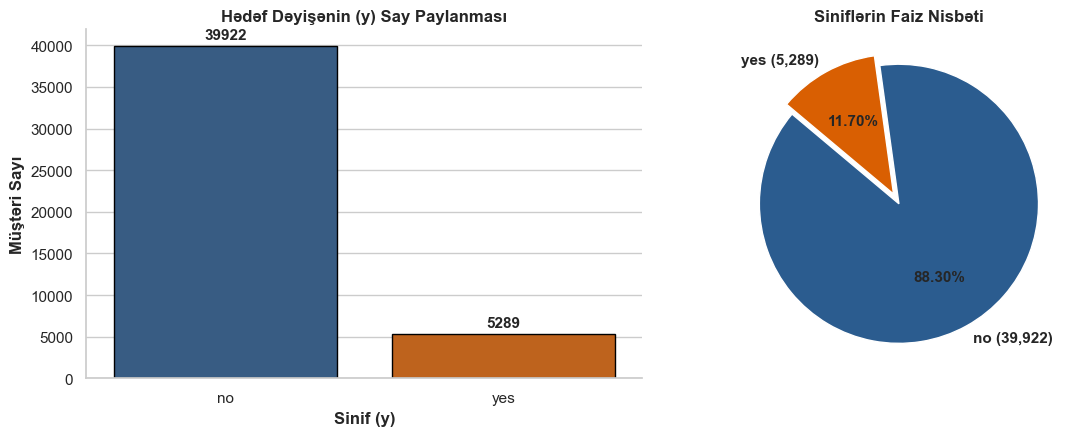

In [9]:
# Hədəf dəyişənin balanssızlığının vizual təsviri
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ['#2b5c8f', '#d95f02']

# 1. Sütun qrafiki (Countplot)
sns.countplot(data=data, x='y', hue='y', palette=colors, legend=False, ax=axes[0], edgecolor='black')
axes[0].set_title('Hədəf Dəyişənin (y) Say Paylanması', fontweight='bold')
axes[0].set_xlabel('Sinif (y)', fontweight='bold')
axes[0].set_ylabel('Müştəri Sayı', fontweight='bold')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', fontweight='bold', padding=3)

# 2. Dairəvi diaqram (Pie chart)
axes[1].pie(
    counts, labels=[f"no ({counts['no']:,})", f"yes ({counts['yes']:,})"],
    autopct='%1.2f%%', startangle=140, colors=colors, explode=(0, 0.08),
    textprops={'fontweight': 'bold'}
)
axes[1].set_title('Siniflərin Faiz Nisbəti', fontweight='bold')

sns.despine(ax=axes[0])
plt.tight_layout()
plt.show()

## 4. Əlamətlərin Seçilməsi və Hazırlanması

`NearMiss` və `SMOTE` kimi alqoritmlər əlamətlər fəzasında **Evklid məsafəsi** hesabladığı üçün yalnız ədədi (`numeric`) dəyişənlər üzərində işləyir (kateqorik dəyişənlər varsa, əvvəlcədən `OneHotEncoder` ilə kodlaşdırılmalıdır).

> [!WARNING]
> **`id` sütununun çıxarılması:** `id` sadəcə müştərinin sıra nömrəsidir və heç bir proqnozlaşdırıcı məna daşımır. Əgər saxlanılarsa, məsafə hesablamalarını təhrif edəcək.

Həmçinin bütün resampling üsullarının nəticələrini vahid formatda yoxlamaq üçün köməkçi `check_balance()` funksiyası yaradırıq.

In [10]:
# Yalnız ədədi sütunları seçirik və texniki 'id' sütununu çıxarırıq
x = data.select_dtypes(include=['number']).drop(columns=['id'])
y = data['y']

print(f"Seçilmiş ədədi əlamətlər ({x.shape[1]} ədəd): {list(x.columns)}")
print(f"X ölçüsü: {x.shape} | y ölçüsü: {y.shape}")

# Resampling nəticələrini səliqəli çap etmək üçün köməkçi funksiya
def show_resampling_result(method_name, y_before, y_after):
    before_counts = y_before.value_counts()
    after_counts = y_after.value_counts()
    df_res = pd.DataFrame({
        'Əvvəl (Orijinal)': before_counts,
        'Sonra (Resampled)': after_counts,
        'Fərq (Dəyişiklik)': after_counts - before_counts,
        'Yeni Pay (%)': (y_after.value_counts(normalize=True) * 100).round(2)
    })
    print(f"=== {method_name} Nəticəsi ===")
    print(f"Ümumi sətir sayı: {len(y_before):,} -> {len(y_after):,}")
    display(df_res)

Seçilmiş ədədi əlamətlər (7 ədəd): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
X ölçüsü: (45211, 7) | y ölçüsü: (45211,)


---
## 5. NearMiss Under-Sampling (Çoxluq Sinfinin Ağıllı Azaldılması)

**Təsadüfi azaltmadan (`RandomUnderSampler`) fərqli olaraq**, **NearMiss** alqoritmi çoxluq sinfindən (`no`) nümunələri kor-koranə silmir. O, **k-Nearest Neighbors (k-NN)** məsafə hesablamasından istifadə edərək qərar sərhədi (decision boundary) üçün ən informativ olan çoxluq nümunələrini saxlayır.

NearMiss alqoritminin **3 fərqli versiyası** mövcuddur:

1. **NearMiss-1 (`version=1`):**
   Hər bir çoxluq (`no`) nümunəsi üçün azlıq (`yes`) sinfindən olan **ən yaxın $k$ qonşuya** (`n_neighbors=3`) qədər orta Evklid məsafəsini hesablayır və bu orta məsafəsi **ən kiçik olan** çoxluq nümunələrini seçir.
   * *Xüsusiyyəti:* Qərar sərhədinə ən yaxın nöqtələri saxlayır, lakin azlıq sinfində kənarlaşmalar (noise/outliers) varsa, onların ətrafındakı nöqtələri seçməyə meyllidir.

2. **NearMiss-2 (`version=2`):**
   Hər bir çoxluq (`no`) nümunəsi üçün azlıq (`yes`) sinfindən olan **ən uzaq $k$ qonşuya** (`n_neighbors=3`) qədər orta məsafəni hesablayır və bu məsafəsi **ən kiçik olan** çoxluq nümunələrini saxlayır.
   * *Xüsusiyyəti:* Tək-tük səs-küylü nöqtələrə deyil, azlıq sinfinin ümumi paylanma mərkəzinə ən yaxın olan çoxluq nümunələrini seçir.

3. **NearMiss-3 (`version=3`):**
   İki mərhələli alqoritmdir:
   * **Mərhələ 1:** Hər bir azlıq (`yes`) nümunəsi üçün ona ən yaxın olan `n_neighbors_ver3` (məsələn, $3$) sayda çoxluq nümunəsi namizəd siyahısına salınır. Bu, hər bir azlıq nöqtəsinin ətrafında çoxluq nümunələrinin olmasını təmin edir.
   * **Mərhələ 2:** Namizəd siyahısındakı çoxluq nümunələri içərisindən $k$ ən yaxın azlıq qonşusuna orta məsafəsi **ən böyük olanlar** seçilir.
   * *Qeyd:* Əgər müxtəlif azlıq nümunələrinin ən yaxın qonşuları üst-üstə düşərsə (kəsişərsə), 1-ci mərhələdə toplanan unikal namizəd sayı $N_{\text{minority}}$-dən az ola bilər.

### 5.1. NearMiss — Versiya 1 (`version=1`)

In [11]:
# NearMiss Versiya 1: Ən yaxın 3 azlıq qonşusuna orta məsafəsi ən kiçik olan çoxluq nümunələrini seçir
undersampling_nm1 = NearMiss(version=1, n_neighbors=3)
X_nm1, Y_nm1 = undersampling_nm1.fit_resample(x, y)

show_resampling_result("NearMiss (Version 1)", y, Y_nm1)

=== NearMiss (Version 1) Nəticəsi ===
Ümumi sətir sayı: 45,211 -> 10,578


,Əvvəl (Orijinal),Sonra (Resampled),Fərq (Dəyişiklik),Yeni Pay (%)
y,,,,
no,39922,5289,-34633,50.0
yes,5289,5289,0,50.0


### 5.2. NearMiss — Versiya 2 (`version=2`)

In [12]:
# NearMiss Versiya 2: Ən uzaq 3 azlıq qonşusuna orta məsafəsi ən kiçik olan çoxluq nümunələrini seçir
undersampling_nm2 = NearMiss(version=2, n_neighbors=3)
X_nm2, Y_nm2 = undersampling_nm2.fit_resample(x, y)

show_resampling_result("NearMiss (Version 2)", y, Y_nm2)

=== NearMiss (Version 2) Nəticəsi ===
Ümumi sətir sayı: 45,211 -> 10,578


,Əvvəl (Orijinal),Sonra (Resampled),Fərq (Dəyişiklik),Yeni Pay (%)
y,,,,
no,39922,5289,-34633,50.0
yes,5289,5289,0,50.0


### 5.3. NearMiss — Versiya 3 (`version=3`)

In [13]:
# NearMiss Versiya 3: Əvvəlcə hər azlıq nöqtəsi üçün 3 ən yaxın çoxluq namizədi seçir,
# sonra onlar arasından orta məsafəsi ən böyük olanları saxlayır
undersampling_nm3 = NearMiss(version=3, n_neighbors_ver3=3)
X_nm3, Y_nm3 = undersampling_nm3.fit_resample(x, y)

show_resampling_result("NearMiss (Version 3)", y, Y_nm3)

=== NearMiss (Version 3) Nəticəsi ===
Ümumi sətir sayı: 45,211 -> 10,578


,Əvvəl (Orijinal),Sonra (Resampled),Fərq (Dəyişiklik),Yeni Pay (%)
y,,,,
no,39922,5289,-34633,50.0
yes,5289,5289,0,50.0


---
## 6. SMOTE (Synthetic Minority Over-Sampling Technique)

Under-sampling zamanı $39,922$ ədəd `no` nümunəsindən $34,633$-ü silinir ki, bu da böyük həcmdə informasiya itkisinə səbəb olur. Bunun əvəzinə **Over-sampling** yanaşması çoxluq sinfinə toxunmadan azlıq sinfini (`yes`) artırır.

Sadə təkrarlama (`RandomOverSampler`) eyni sətirləri kopyaladığı üçün modeldə **ifrat öyrənmə (overfitting)** yaradır. **SMOTE** (Chawla et al., 2002) isə mövcud azlıq nümunələri arasında **xətti interpolyasiya** apararaq tamamilə yeni, sintetik nümunələr generasiya edir:

### Riyazi Alqoritmi:
1. Azlıq sinfindən hər hansı $\mathbf{x}_i$ vektoru götürülür.
2. Yalnız azlıq sinfi daxilində həmin $\mathbf{x}_i$ nöqtəsinə ən yaxın olan $k$ qonşu (`k_neighbors=5`) tapılır.
3. Bu $k$ qonşudan təsadüfi biri ($\mathbf{x}_{zi}$) seçilir.
4. İki nöqtəni birləşdirən düz xətt parçası üzərində təsadüfi $\lambda \sim U(0, 1)$ ədədi ilə yeni sintetik nöqtə yaradılır:

$$
\mathbf{x}_{\text{new}} = \mathbf{x}_i + \lambda \cdot (\mathbf{x}_{zi} - \mathbf{x}_i), \quad \lambda \in [0, 1]
$$

> [!TIP]
> **Təkrarolunmazlıq (Reproducibility):** SMOTE daxilində təsadüfi qonşu və $\lambda$ seçildiyi üçün hər işə salındıqda eyni nəticəni almaq məqsədilə mütləq `random_state=42` parametri təyin edilməlidir.

In [14]:
# Klassik SMOTE: k_neighbors=5 yaxın qonşu arasında xətti interpolyasiya
oversample_smote = SMOTE(k_neighbors=5, random_state=42)
X_smote, Y_smote = oversample_smote.fit_resample(x, y)

show_resampling_result("SMOTE", y, Y_smote)

=== SMOTE Nəticəsi ===
Ümumi sətir sayı: 45,211 -> 79,844


,Əvvəl (Orijinal),Sonra (Resampled),Fərq (Dəyişiklik),Yeni Pay (%)
y,,,,
no,39922,39922,0,50.0
yes,5289,39922,34633,50.0


---
## 7. Borderline-SMOTE (Sərhədyanı Sintetik Artırma)

Klassik SMOTE alqoritminin əsas zəifliyi odur ki, o, azlıq sinfinin **bütün** nöqtələrinə eyni yanaşır:
- Sinfin tam mərkəzində yerləşən **təhlükəsiz (safe)** nöqtələr qərar sərhədinə heç bir töhfə vermir.
- Çoxluq sinfinin dərinliyinə düşmüş tək-tük **səs-küylü (noise)** azlıq nöqtələri arasında xətt çəkdikdə isə yeni sintetik nöqtələr birbaşa çoxluq sinfinin üzərinə düşür və siniflərin bir-birinə qarışmasına (class overlapping) səbəb olur.

**Borderline-SMOTE** (Han et al., 2005) bu problemi həll etmək üçün əvvəlcə hər bir azlıq nöqtəsinin $\mathbf{x}_i$ ətrafındakı **bütün siniflərdən olan $m$ ən yaxın qonşusuna** (`m_neighbors=10`) baxır və həmin qonşular içərisində çoxluq (`no`) sinfinə aid olanların sayını ($m'$) hesablayır:

1. **Noise (Səs-küy):** Əgər $m' = m$ olarsa (bütün $10$ qonşusu `no` sinfidir) $\rightarrow$ Bu nöqtə kənarlaşmadır, **sintetik nümunə yaradılmır**.
2. **Safe (Təhlükəsiz):** Əgər $0 \le m' < \frac{m}{2}$ olarsa (qonşuların yarısından çoxu öz `yes` sinfidir) $\rightarrow$ Bu nöqtə təhlükəsiz bölgədədir, **sintetik nümunə yaradılmır**.
3. **Danger (Təhlükə / Sərhəd):** Əgər $\frac{m}{2} \le m' < m$ olarsa (qonşuların yarısından çoxu əks sinifdir, lakin hamısı deyil) $\rightarrow$ Bu nöqtə **qərar sərhədindədir (Borderline)**! Yalnız bu **"Danger"** çoxluğuna düşən nümunələr üzərindən SMOTE interpolyasiyası (`k_neighbors=5`) aparılır.

* **`kind='borderline-1'` (Default):** "Danger" nöqtələrini yalnız öz azlıq (`yes`) qonşuları ilə interpolyasiya edir.
* **`kind='borderline-2'`:** "Danger" nöqtələrini həm azlıq, həm də çoxluq qonşuları ilə ($\lambda \in [0, 0.5]$) interpolyasiya edir.

In [15]:
# Borderline-SMOTE: Yalnız sərhəddə ('Danger' zonasında) yerləşən azlıq nümunələrini artırır
oversample_bsmote = BorderlineSMOTE(k_neighbors=5, m_neighbors=10, kind='borderline-1', random_state=42)
X_bsmote, Y_bsmote = oversample_bsmote.fit_resample(x, y)

show_resampling_result("Borderline-SMOTE (borderline-1)", y, Y_bsmote)

=== Borderline-SMOTE (borderline-1) Nəticəsi ===
Ümumi sətir sayı: 45,211 -> 79,844


,Əvvəl (Orijinal),Sonra (Resampled),Fərq (Dəyişiklik),Yeni Pay (%)
y,,,,
no,39922,39922,0,50.0
yes,5289,39922,34633,50.0


---
## 8. SVM-SMOTE (Support Vector Machine SMOTE)

**SVM-SMOTE** (Nguyen et al., 2011) qərar sərhədini tapmaq üçün $k$-NN evristikası əvəzinə **Dəstək Vektorları Maşını (`SVM`)** alqoritmindən istifadə edir.

### İşləmə Mexanizmi:
1. Verilənlər üzərində bir `SVC` (Support Vector Classifier) modeli öyrədilir.
2. SVM nəzəriyyəsinə görə, iki sinfi ayıran hiper-müstəviyə (qərar sərhədinə) ən yaxın olan kritik nöqtələr **Dəstək Vektorlarıdır (Support Vectors)**.
3. Alqoritm yalnız azlıq sinfinə (`yes`) aid olan **dəstək vektorlarını** seçir və onların $k$ ən yaxın azlıq qonşusu (`k_neighbors=5`) ilə yeni sintetik nümunələr yaradır:
   * Əgər dəstək vektorunun ətrafındakı `m_neighbors=10` qonşunun yarısından azı çoxluq sinfidirsə, sərhədi genişləndirmək üçün **ekstrapolyasiya** (`out_step=0.5` addımı ilə çoxluq sinfinə doğru) aparılır.
   * Əks halda (ətrafda çoxluq sinfi sıxdırsa), daxilə doğru standart **interpolyasiya** aparılır.

In [16]:
# SVM-SMOTE: SVM Dəstək Vektorları ətrafında sintetik nümunələrin yaradılması
oversample_svmsmote = SVMSMOTE(k_neighbors=5, m_neighbors=10, out_step=0.5, random_state=42)
X, Y = oversample_svmsmote.fit_resample(x, y)

show_resampling_result("SVM-SMOTE", y, Y)

=== SVM-SMOTE Nəticəsi ===
Ümumi sətir sayı: 45,211 -> 79,844


,Əvvəl (Orijinal),Sonra (Resampled),Fərq (Dəyişiklik),Yeni Pay (%)
y,,,,
no,39922,39922,0,50.0
yes,5289,39922,34633,50.0


---
## 9. Bütün Resampling Metodlarının 2D Fəzada Vizual Müqayisəsi (PCA)

Yuxarıdakı 6 fərqli metodun (`NearMiss-1, 2, 3`, `SMOTE`, `Borderline-SMOTE`, `SVM-SMOTE`) verilənlər fəzasını necə dəyişdirdiyini gözlə görmək üçün:
1. Əlamətləri `StandardScaler` ilə standartlaşdırırıq (orta $= 0$, standart kənarlaşma $= 1$).
2. **PCA (Principal Component Analysis)** vasitəsilə $7$ ölçülü əlamətlər fəzasını $2$ əsas komponentə (`PC1` və `PC2`) proyeksiya edirik.

In [18]:
# Miqyaslama və 2 ölçülü PCA proyeksiyası
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

x_scaled

array([[ 1.60696496,  0.25641925, -1.29847633, ..., -0.56935064,
        -0.41145311, -0.25194037],
       [ 0.28852927, -0.43789469, -1.29847633, ..., -0.56935064,
        -0.41145311, -0.25194037],
       [-0.74738448, -0.44676247, -1.29847633, ..., -0.56935064,
        -0.41145311, -0.25194037],
       ...,
       [ 2.92540065,  1.42959305,  0.14341818, ...,  0.72181052,
         1.43618859,  1.05047333],
       [ 1.51279098, -0.22802402,  0.14341818, ...,  0.39902023,
        -0.41145311, -0.25194037],
       [-0.37068857,  0.52836436,  0.14341818, ..., -0.24656035,
         1.4761376 ,  4.52357654]])

In [20]:
pca = PCA(n_components=2, random_state=42)
x_pca = pca.fit_transform(x_scaled)

x_pca

array([[ 0.03370712, -1.40282727],
       [ 0.01758882, -0.95447819],
       [ 0.02293815, -0.69963239],
       ...,
       [ 1.58567726, -0.95505725],
       [-0.55920985, -0.42283585],
       [ 3.95646377,  1.31928541]])

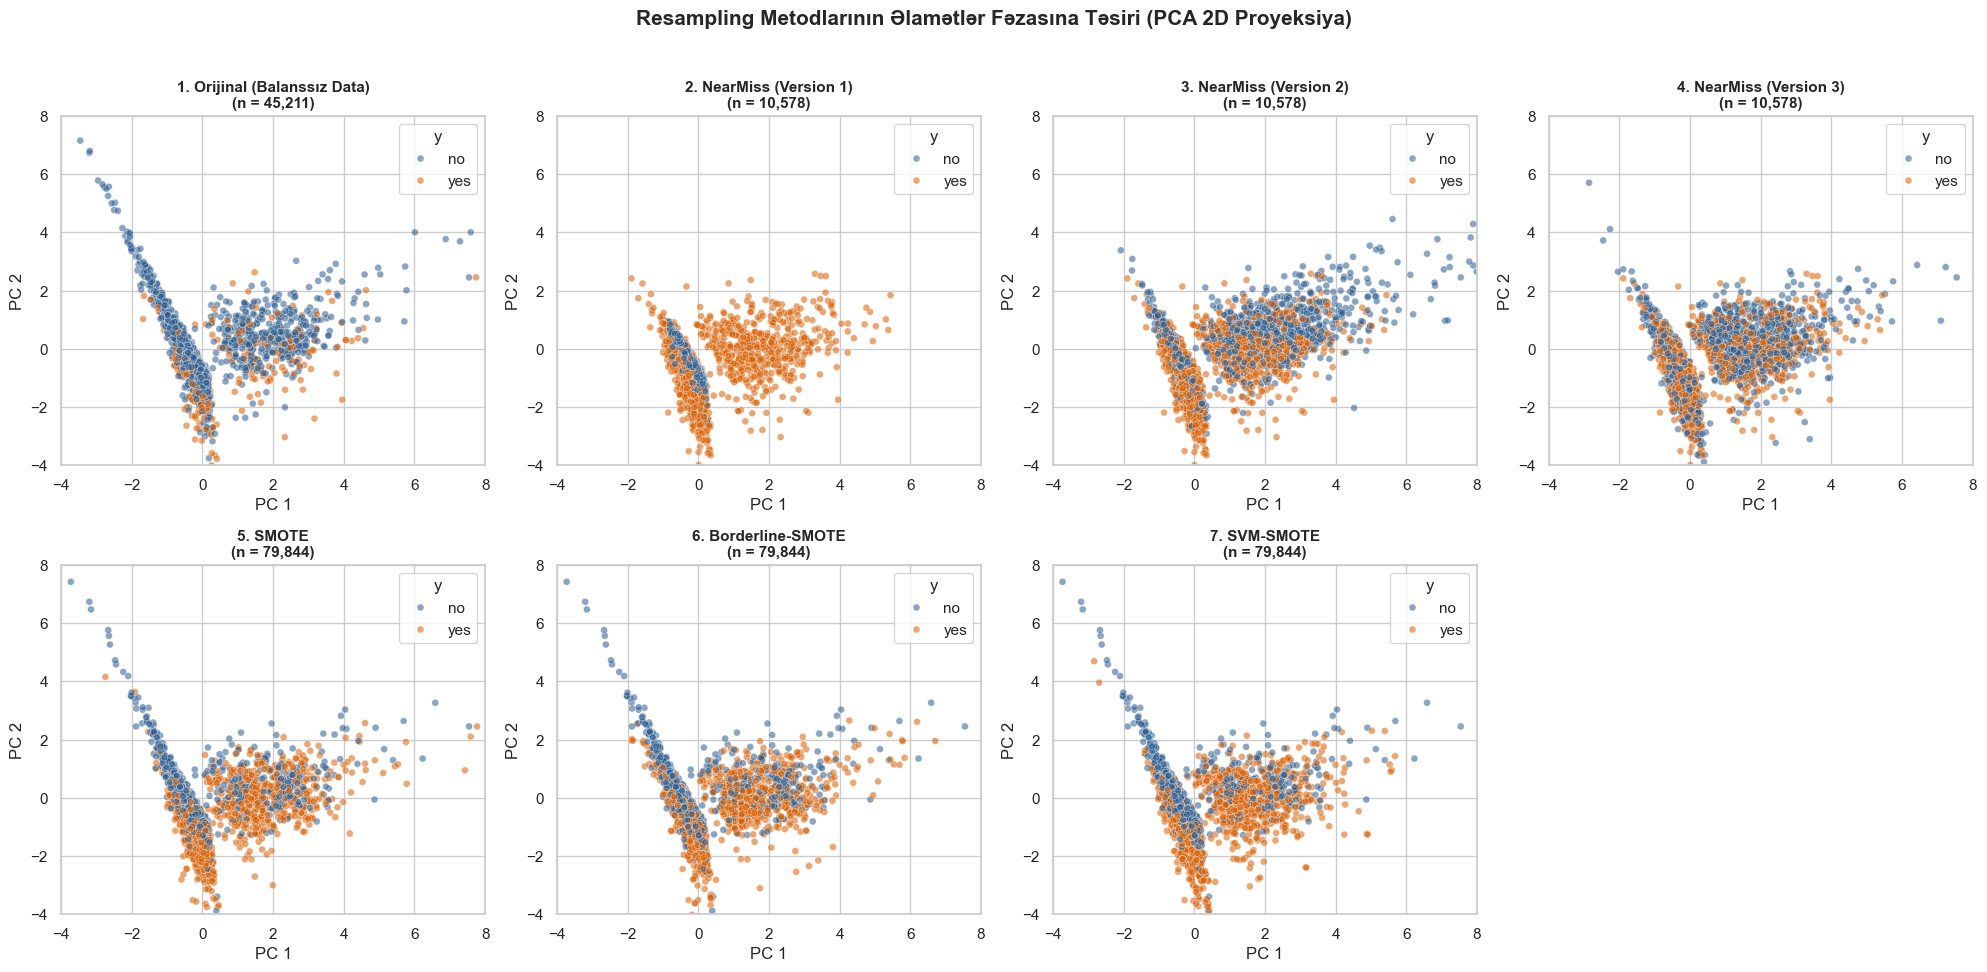

In [21]:
# Miqyaslanmış data üzərində bütün metodları tətbiq edib vizuallaşdırırıq
samplers = {
    '1. Orijinal (Balanssız Data)': None,
    '2. NearMiss (Version 1)': NearMiss(version=1, n_neighbors=3),
    '3. NearMiss (Version 2)': NearMiss(version=2, n_neighbors=3),
    '4. NearMiss (Version 3)': NearMiss(version=3, n_neighbors_ver3=3),
    '5. SMOTE': SMOTE(random_state=42),
    '6. Borderline-SMOTE': BorderlineSMOTE(random_state=42),
    '7. SVM-SMOTE': SVMSMOTE(random_state=42)
}

fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
axes = axes.flatten()

for idx, (title, sampler) in enumerate(samplers.items()):
    ax = axes[idx]
    if sampler is None:
        X_res_pca, y_res = x_pca, y
    else:
        X_res_scaled, y_res = sampler.fit_resample(x_scaled, y)
        X_res_pca = pca.transform(X_res_scaled)
        
    # Qrafikdə aydın görünməsi üçün təsadüfi alt-seçim (maksimum 3000 nöqtə)
    rng = np.random.RandomState(42)
    sample_idx = rng.choice(len(y_res), size=min(3000, len(y_res)), replace=False)
    
    sns.scatterplot(
        x=X_res_pca[sample_idx, 0],
        y=X_res_pca[sample_idx, 1],
        hue=y_res.iloc[sample_idx],
        hue_order=['no', 'yes'],
        palette={'no': '#2b5c8f', 'yes': '#d95f02'},
        alpha=0.55,
        s=25,
        ax=ax
    )
    ax.set_title(f"{title}\n(n = {len(y_res):,})", fontweight='bold', fontsize=11)
    ax.set_xlabel('PC 1')
    ax.set_ylabel('PC 2')
    ax.set_xlim(-4, 8)
    ax.set_ylim(-4, 8)

# Sonuncu boş alt-qrafiki gizlədirik
axes[-1].axis('off')
plt.suptitle('Resampling Metodlarının Əlamətlər Fəzasına Təsiri (PCA 2D Proyeksiya)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 10. Mükəmməl Praktika (Best Practice): Data Leakage Olmadan Modelləşdirmə və Müqayisə

Yuxarıdakı bölmələrdə alqoritmlərin işləmə mexanizmini görmək üçün `fit_resample(x, y)` funksiyasını bütün datasetə tətbiq etdik. Lakin **real maşın öyrənməsi layihələrində** bu, ciddi metodoloji xətaya (**Data Leakage — Məlumat Sızması**) gətirib çıxarır:
- Əgər `train_test_split`-dən **əvvəl** `SMOTE` tətbiq etsək, yaradılan sintetik nöqtələr həm `train`, həm də `test` dəstinə düşəcək. Nəticədə model test dəstindəki məlumatları əvvəlcədən "görmüş" olacaq və süni şəkildə yüksək nəticə göstərəcək.
- Eyni zamanda `NearMiss` və `SMOTE` məsafə hesabladığı üçün **əvvəlcə `StandardScaler`**, daha sonra **Resampling**, ən sonda isə **Model (`Classifier`)** işə düşməlidir.

Bunun üçün `imblearn.pipeline.Pipeline` istifadə edilir. Bu boru xətti (`Pipeline`) avtomatik olaraq:
1. Təlim (`fit`) zamanı: `StandardScaler` $\rightarrow$ `Sampler (SMOTE / NearMiss)` $\rightarrow$ `Model` ardıcıllığını yalnız **Train** dəstində icra edir.
2. Proqnoz (`predict`) zamanı: `Sampler` addımını **ötürür** və **Test** dəstini olduğu kimi (real balanssız halda) qiymətləndirir!

In [22]:
# 1. Hədəf dəyişəni 0 ('no') və 1 ('yes') olaraq kodlaşdırırıq
y_binary = (y == 'yes').astype(int)

# 2. Datanı Stratifikasiyalı (sinif nisbətini qoruyaraq) Train (80%) və Test (20%) hissələrinə bölürük
X_train, X_test, y_train, y_test = train_test_split(
    x, y_binary, test_size=0.20, stratify=y_binary, random_state=42
)

print(f"Train ölçüsü: {X_train.shape[0]:,} (yes: {y_train.sum():,}) | Test ölçüsü: {X_test.shape[0]:,} (yes: {y_test.sum():,})\n")

Train ölçüsü: 36,168 (yes: 4,231) | Test ölçüsü: 9,043 (yes: 1,058)



In [ ]:
# 3. Müqayisə ediləcək Resampling strategiyaları
strategies = {
    'Orijinal (Balanssız)': None,
    'NearMiss-1': NearMiss(version=1, n_neighbors=3),
    'NearMiss-2': NearMiss(version=2, n_neighbors=3),
    'NearMiss-3': NearMiss(version=3, n_neighbors_ver3=3),
    'SMOTE': SMOTE(random_state=42),
    'Borderline-SMOTE': BorderlineSMOTE(random_state=42),
    'SVM-SMOTE': SVMSMOTE(random_state=42)
}

results = []

for name, sampler in strategies.items():
    steps = [('scaler', StandardScaler())]
    if sampler is not None:
        steps.append(('sampler', sampler))
    steps.append(('classifier', LogisticRegression(max_iter=1000, random_state=42)))
    
    pipeline = ImbPipeline(steps=steps)
    pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    
    results.append({
        'Metod': name,
        'Precision (Class 1)': precision_score(y_test, y_pred),
        'Recall (Class 1)': recall_score(y_test, y_pred),
        'F1-Score (Class 1)': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

In [24]:
results_df = pd.DataFrame(results).set_index('Metod').round(4)
results_df

,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),ROC-AUC
Metod,,,,
Orijinal (Balanssız),0.5686,0.1607,0.2506,0.8305
NearMiss-1,0.1736,0.8166,0.2863,0.6963
NearMiss-2,0.1247,0.8251,0.2167,0.6555
NearMiss-3,0.1495,0.6096,0.2401,0.6355
SMOTE,0.3187,0.6938,0.4368,0.8324
Borderline-SMOTE,0.3152,0.6994,0.4345,0.8328
SVM-SMOTE,0.3401,0.6465,0.4457,0.8315


In [26]:
# Modelləşdirmə nəticələrinin vizual müqayisəsi
results_melted = results_df.reset_index().melt(
    id_vars='Metod', 
    value_vars=['Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)', 'ROC-AUC'],
    var_name='Metrika', 
    value_name='Dəyər'
)

results_melted

,Metod,Metrika,Dəyər
0,Orijinal (Balanssız),Precision (Class 1),0.5686
1,NearMiss-1,Precision (Class 1),0.1736
2,NearMiss-2,Precision (Class 1),0.1247
3,NearMiss-3,Precision (Class 1),0.1495
4,SMOTE,Precision (Class 1),0.3187
5,Borderline-SMOTE,Precision (Class 1),0.3152
6,SVM-SMOTE,Precision (Class 1),0.3401
7,Orijinal (Balanssız),Recall (Class 1),0.1607
8,NearMiss-1,Recall (Class 1),0.8166
9,NearMiss-2,Recall (Class 1),0.8251


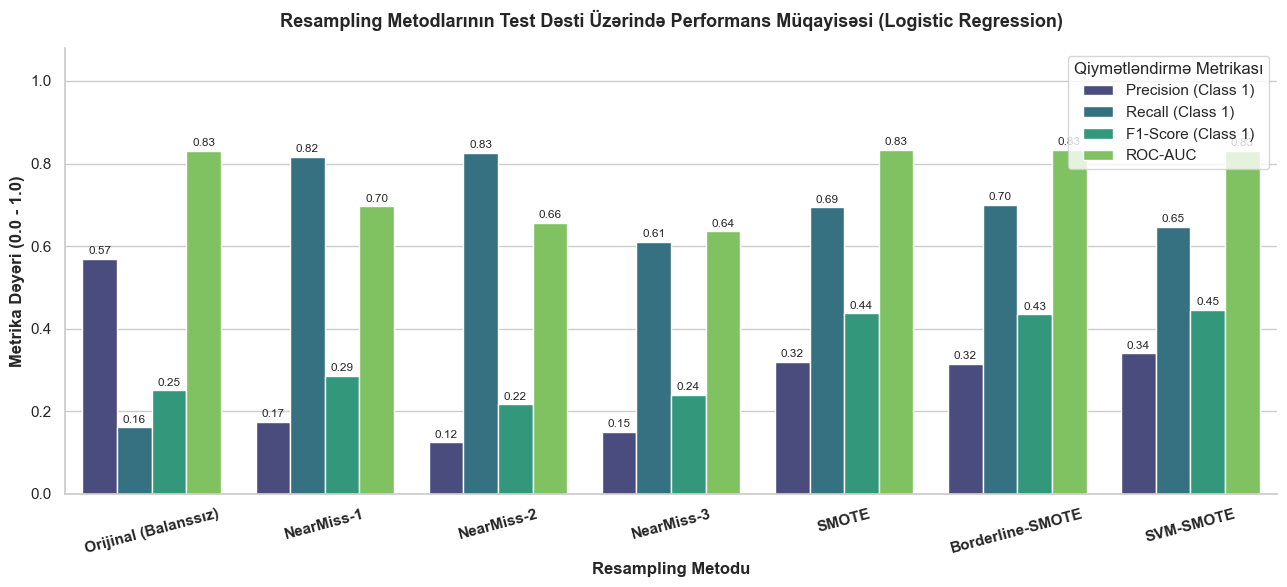

In [27]:
plt.figure(figsize=(13, 6))
ax = sns.barplot(data=results_melted, x='Metod', y='Dəyər', hue='Metrika', palette='viridis')

plt.title('Resampling Metodlarının Test Dəsti Üzərində Performans Müqayisəsi (Logistic Regression)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Resampling Metodu', fontweight='bold')
plt.ylabel('Metrika Dəyəri (0.0 - 1.0)', fontweight='bold')
plt.ylim(0, 1.08)
plt.xticks(rotation=15, fontweight='bold')
plt.legend(loc='upper right', frameon=True, title='Qiymətləndirmə Metrikası')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8.5, padding=2)

sns.despine()
plt.tight_layout()
plt.show()

### Yekun Nəticə və Tövsiyələr

1. **Orijinal (Balanssız) Data:** Model çoxluq sinfinə (`no`) meylli olduğu üçün `Recall` çox aşağı qalır (gedən müştərilərin böyük əksəriyyətini qaçırır).
2. **NearMiss (Under-sampling):** Çoxluq sinfini kəskin azaldaraq `Recall`-u yüksəldir, lakin $34,000$-dən çox sətir silindiyi üçün çoxluq sinfinin strukturunu itirir və `False Positive` sayını artıraraq `Precision` və `ROC-AUC` dəyərlərini aşağı salır (xüsusilə `NearMiss-1` və `NearMiss-2`). `NearMiss-3` sərhəd namizədlərini daha diqqətli seçdiyi üçün digər iki versiyadan daha stabil nəticə verir.
3. **SMOTE / Borderline-SMOTE / SVM-SMOTE (Over-sampling):** Heç bir məlumat itkisinə yol vermədən azlıq sinfini sintetik olaraq zənginləşdirir. Nəticədə həm yüksək **ROC-AUC**, həm yüksək **Recall**, həm də balanslı **F1-Score** əldə edilir.